In [3]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [4]:
# Load CSV
csv_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/wandb_export_2026-03-24T15_22_30.838-04_00.csv"
)
raw = pd.read_csv(csv_path)

TARGET_STEPS = 600_000_000

# Parse run columns: extract radius, mode, seed from column names
# Pattern: Tminr<radius>_<mode>_s<seed>_<runid> - eval/episode_mean_collected_treats
pattern = re.compile(
    r"^Tminr([\d.]+)_(.+?)_s(\d+)_.+ - eval/episode_mean_collected_treats$"
)

records = []
for col in raw.columns:
    m = pattern.match(col)
    if m:
        radius = float(m.group(1))
        mode = m.group(2)
        seed = int(m.group(3))
        # Get value at the row closest to TARGET_STEPS where this run has data
        vals = pd.to_numeric(raw[col], errors="coerce")
        valid_mask = vals.notna()
        if valid_mask.any():
            valid_indices = raw.index[valid_mask]
            closest_idx = valid_indices[
                (raw.loc[valid_indices, "num_steps"] - TARGET_STEPS).abs().argmin()
            ]
            val = vals.loc[closest_idx]
            records.append(
                {
                    "radius": radius,
                    "mode": mode,
                    "seed": seed,
                    "collected_treats": val,
                    "num_steps": raw.loc[closest_idx, "num_steps"],
                }
            )

df = pd.DataFrame(records)

# Map mode names to display names
mode_map = {
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
    "scratch": "Scratch",
}
df["Training Mode"] = df["mode"].map(mode_map)
df = df.sort_values("radius")
df

,radius,mode,seed,collected_treats,num_steps,Training Mode
25,0.0,decoder_only,0,5.093750,600637440,Decoder-Only
30,0.0,decoder_only,1,4.992188,600637440,Decoder-Only
21,0.0,decoder_only,2,4.968750,600637440,Decoder-Only
56,0.0,prior_decoder,0,8.828125,600637440,Prior-Enabled
55,0.0,prior_decoder,1,8.976562,600637440,Prior-Enabled
...,...,...,...,...,...,...
24,1.5,prior_decoder,1,9.820312,600637440,Prior-Enabled
57,1.5,scratch,1,0.000000,600637440,Scratch
59,1.5,scratch,0,0.000000,600637440,Scratch
53,1.5,scratch,2,0.000000,600637440,Scratch


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/arena_forage_collected_treats.[pdf|svg|png]


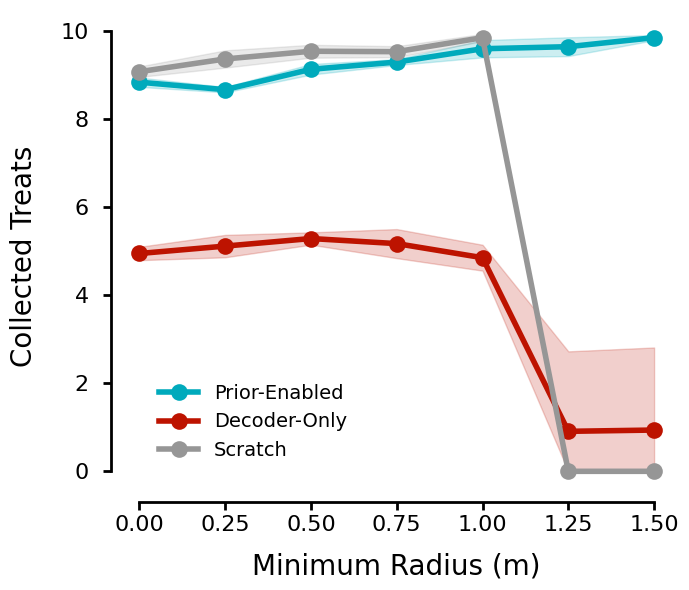

In [18]:
hue_order = ["Prior-Enabled", "Decoder-Only", "Scratch"]
palette = {
    "Prior-Enabled": tuple(c / 255 for c in (0, 170, 188)),
    "Decoder-Only": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}

save_name = "arena_forage_collected_treats"

fig, ax_main = plt.subplots(figsize=(7, 6))

# --- Main plot ---
sns.lineplot(
    data=df,
    x="radius",
    y="collected_treats",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    ax=ax_main,
)

# Clip error band shading to y >= 0
for child in ax_main.get_children():
    if isinstance(child, plt.matplotlib.collections.PolyCollection):
        paths = child.get_paths()
        for path in paths:
            path.vertices[:, 1] = np.clip(path.vertices[:, 1], 0, None)

ax_main.set_ylim(bottom=-0.7)
ax_main.set_xlabel("Minimum Radius (m)", fontsize=20, labelpad=12)
ax_main.set_ylabel("Collected Treats", fontsize=20, labelpad=16)
ax_main.tick_params(labelsize=16, width=2, length=6)
ax_main.tick_params(axis="y", pad=10)

# Remove top and right spines
sns.despine(ax=ax_main)

# Trim spines to data range
xticks = ax_main.get_xticks()
yticks = ax_main.get_yticks()
xlim = ax_main.get_xlim()
ylim = ax_main.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]

ax_main.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax_main.spines["left"].set_bounds(yticks[0], yticks[-1])

# Shift y-axis spine to the left
ax_main.spines["left"].set_position(("outward", 2))

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax_main.spines[spine].set_linewidth(2)

ax_main.legend(
    fontsize=14, frameon=False, loc="lower left", bbox_to_anchor=(0.05, 0.05)
)

plt.tight_layout()

# Save
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()

In [2]:
import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import json

import jax
import jax.numpy as jnp
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import arena_forage

from scamper.agent.task_transfer.arena_forage.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.arena_forage.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.arena_forage.scratch_networks import (
    make_scratch_ppo_networks,
)

In [14]:
# --- Configuration: set checkpoint path here ---
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/arena_forage_checkpoints/260318_004143_806487"
EPISODE_LENGTH = 2000
SEED = 42

# Override environment radii (set to None to use checkpoint defaults)
MIN_SPAWN_RADIUS = 1.0
SPAWN_RADIUS = 2.0

In [15]:
def load_model(
    checkpoint_path, checkpoint_step=None, min_spawn_radius=None, spawn_radius=None
):
    """Load a trained arena_forage model and return everything needed for rollouts."""
    from mujoco import mjx

    ckpt_info = load_task_transfer_metadata(checkpoint_path, step=checkpoint_step)
    config = ckpt_info["config"]
    ckpt_step = ckpt_info["step"]
    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    print(f"Loading checkpoint: {checkpoint_path}")
    print(f"  Mode: {mode}, Step: {ckpt_step}")

    # Load frozen networks from prior checkpoint
    prior_checkpoint_path = config["checkpoint"]["path"]
    prior_checkpoint_step = config["checkpoint"]["step"]

    (
        encoder_params,
        prior_params,
        decoder_params,
        normalizer_params,
        _,
    ) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
    action_size = ckpt_cfg["network_config"]["action_size"]

    # Create environment
    env_cfg = arena_forage.default_config()
    xml_variant = config["env"].get("xml_variant", "full-collisions")
    if xml_variant == "limited-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
    elif xml_variant == "full-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
    elif xml_variant == "no-tail-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]

    # Arena forage parameters
    env_cfg.num_treats = config["env"]["num_treats"]
    env_cfg.treat_sphere_radius = config["env"]["treat_sphere_radius"]
    env_cfg.treat_height = config["env"]["treat_height"]
    env_cfg.min_spawn_radius = (
        config["env"]["min_spawn_radius"]
        if min_spawn_radius is None
        else min_spawn_radius
    )
    env_cfg.spawn_radius = (
        config["env"]["spawn_radius"] if spawn_radius is None else spawn_radius
    )
    env_cfg.scent_sigma = config["env"]["scent_sigma"]

    if min_spawn_radius is not None or spawn_radius is not None:
        print(
            f"  Radius overrides: min_spawn_radius={env_cfg.min_spawn_radius}, spawn_radius={env_cfg.spawn_radius}"
        )

    if config["env"].get("reward_weights"):
        env_cfg.reward_terms = {
            "treat_collection": {
                "weight": config["env"]["reward_weights"]["treat_collection"]
            },
            "scent_proximity": {
                "weight": config["env"]["reward_weights"]["scent_proximity"]
            },
        }

    if mode == "scratch":
        env_cfg.torque_actuators = config.get("scratch", {}).get(
            "torque_actuators", True
        )
    else:
        env_cfg.torque_actuators = True

    # Create decoder inference function and wrap environment
    decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
    base_env = arena_forage.ArenaForage(config=env_cfg)
    base_env._mjx_model = mjx.put_model(base_env._mj_model, impl=env_cfg.mujoco_impl)

    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    elif mode == "prior_decoder":
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=config["prior_decoder"]["deterministic_prior"],
            noise_logvar=config["prior_decoder"]["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    # Build network and load parameters
    rng = jax.random.PRNGKey(0)
    start_state = jit_reset(rng)
    obs_size = start_state.obs.shape[-1]
    normalize = running_statistics.normalize
    policy_action_size = env.action_size

    if mode == "scratch":

        def network_factory(*args, **kwargs):
            return make_scratch_ppo_networks(
                obs_size=obs_size,
                action_size=policy_action_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        checkpoint_path, abstract_brax_params, step=ckpt_step
    )

    # Create deterministic inference function
    if mode == "scratch":
        ppo_network = network_factory()
    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

    jit_inference_fn = jax.jit(inference_fn)

    print(f"  Model loaded successfully.")
    return jit_reset, jit_step, jit_inference_fn, brax_params, env, config

In [16]:
# Load model and run rollout, collecting states
jit_reset, jit_step, jit_inference_fn, brax_params, env, config = load_model(
    CHECKPOINT_PATH, min_spawn_radius=MIN_SPAWN_RADIUS, spawn_radius=SPAWN_RADIUS
)

rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

for _ in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)

print(f"Rollout complete: {len(rollout)} frames")
print(f"Treats collected: {np.sum(np.array(rollout[-1].info['treat_collected']))}")

Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/arena_forage_checkpoints/260318_004143_806487
  Mode: scratch, Step: 73
  Radius overrides: min_spawn_radius=1.0, spawn_radius=2.0
  Model loaded successfully.
Rollout complete: 2001 frames
Treats collected: 10


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/arena_forage_trajectory_heatmap_scratch.[pdf|svg|png]


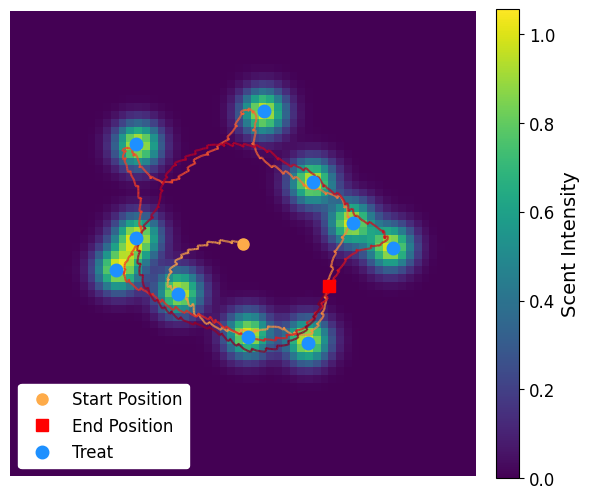

In [17]:
# --- Static 2D trajectory heatmap ---
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap

# Get environment config
base_env = env
while hasattr(base_env, "env"):
    base_env = base_env.env
cfg = base_env._config
mode = config["mode"]

num_treats = cfg.num_treats
sigma = cfg.scent_sigma
spawn_radius = cfg.spawn_radius
extent = spawn_radius * 1.5
grid_resolution = 60

# Pre-compute scent grids per treat (all treats, as if none collected)
grid_1d = np.linspace(-extent, extent, grid_resolution)
gx, gy = np.meshgrid(grid_1d, grid_1d)

treat_pos = np.array(rollout[0].info["treat_positions"])
scent_per_treat = np.zeros((num_treats, grid_resolution, grid_resolution))
for t in range(num_treats):
    dist2 = (gx - treat_pos[t, 0]) ** 2 + (gy - treat_pos[t, 1]) ** 2
    scent_per_treat[t] = np.exp(-dist2 / (2 * sigma**2))

# Full scent field (all treats active)
scent_grid = np.sum(scent_per_treat, axis=0)
vmax = max(float(scent_grid.max()), 1.0)

# Extract rodent xy trajectory
rodent_xy = np.array([np.array(s.data.qpos[:2]) for s in rollout])

# Truncated YlOrRd colormap (skip the whitish low end)
base_cmap = plt.cm.YlOrRd
colors = base_cmap(np.linspace(0.4, 1.0, 256))
traj_cmap = LinearSegmentedColormap.from_list("YlOrRd_trunc", colors)
start_color = traj_cmap(0.0)

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 6))

# Scent heatmap
im = ax.imshow(
    scent_grid,
    extent=[-extent, extent, -extent, extent],
    origin="lower",
    cmap="viridis",
    vmin=0,
    vmax=vmax,
    aspect="equal",
)

# All treat positions (always shown, never disappear)
for t in range(num_treats):
    label = "Treat" if t == 0 else None
    ax.plot(
        treat_pos[t, 0],
        treat_pos[t, 1],
        marker="o",
        color="dodgerblue",
        markersize=8,
        markeredgewidth=2,
        linestyle="None",
        zorder=5,
        label=label,
    )

# Rodent trajectory with color gradient (time)
points = rodent_xy.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
norm = plt.Normalize(0, len(rodent_xy))
lc = LineCollection(segments, cmap=traj_cmap, norm=norm, linewidths=1.5, alpha=0.8)
lc.set_array(np.arange(len(rodent_xy)))
ax.add_collection(lc)

# Start and end markers
ax.plot(
    rodent_xy[0, 0],
    rodent_xy[0, 1],
    "o",
    color=start_color,
    markersize=8,
    linestyle="None",
    zorder=6,
    label="Start Position",
)
ax.plot(
    rodent_xy[-1, 0],
    rodent_xy[-1, 1],
    "s",
    color="red",
    markersize=8,
    linestyle="None",
    zorder=6,
    label="End Position",
)

ax.set_xlim(-extent, extent)
ax.set_ylim(-extent, extent)
ax.axis("off")

# Reorder legend: Start Position, End Position, Treat
handles, labels = ax.get_legend_handles_labels()
order = [
    labels.index("Start Position"),
    labels.index("End Position"),
    labels.index("Treat"),
]
ax.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    fontsize=12,
    loc="lower left",
    frameon=True,
    facecolor="white",
    edgecolor="white",
    framealpha=1.0,
)

# Colorbar for scent field
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Scent Intensity", fontsize=14)
cbar.ax.tick_params(labelsize=12)

plt.tight_layout()

# Save
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
traj_save_name = f"arena_forage_trajectory_heatmap_{mode}"
fig.savefig(save_dir / f"{traj_save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{traj_save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{traj_save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / traj_save_name}.[pdf|svg|png]")

plt.show()

In [ ]:
# --- Render rollout video ---
import imageio
from IPython.display import Video, display

mode = config["mode"]

# Get base env for rendering
base_env = env
while hasattr(base_env, "env"):
    base_env = base_env.env

frames = base_env.render(rollout, camera="close_profile-rodent", height=960, width=1280)

video_path = str(save_dir / f"arena_forage_rollout_{mode}.mp4")
with imageio.get_writer(video_path, fps=50) as writer:
    for frame in frames:
        writer.append_data(frame)

print(f"Saved video to {video_path}")
display(Video(video_path, embed=True))